# pandaICT links and connections

Both **links** and **connections** are parts of the pandaICT data model. 
(NOTE: **bold** text in the following description indicates elements of the data model.)

## Links

**Links** represent physical point-to-point connections at ISO/OSI layers 1 and 2. A single link may be uni- or bidirectional and can transmit any **protocol** that has a mapping onto the link's physical technology. Multiple protocols may be transmitted over a single link. A link may be connected to **devices** or **nodes**. This connection is modeled with **from** / **to** data fields. Links should always be modeled such that the "from->to" communication is downstream and "to->from" is upstream in order to support asymmetric physical technologies. Unidirectional links (e.g. WLAN) may have multiple "to" addresses. If this is the case, the link is called a multicast link. 


## Connections

**Connections** represent end-to-end connections at ISO/OSI layers 3-7. All connections are generally bidirectional. A connection uses a single specific **protocol**. It may be connected to devices or converter nodes. It has **from** / **to** datafields which refer to the connected elements. There are no multicast connections. A connection is used to transmit **information items** which may be modeled as well. In order to retain the origin of the items as they traverse the network, enable routing and define the data package flow direction (important for asymmetric links), connection endpoints (**peers**, must be devices) as well as the information item **producer** per information item may be specified. 

Transmission of information items within the network might using different links, and hop a multitute of nodes along the way. The path an information item takes through the network is not neccessarily always the same. The links used must support the connection's protocol (i.e. there must be a mapping of that protocol onto each link technology used), otherwise the connection will be rendered out of service. 

## Examples 

The following graphic shows a pandaICT network with links and connections. Note that there are no converters (yet). 

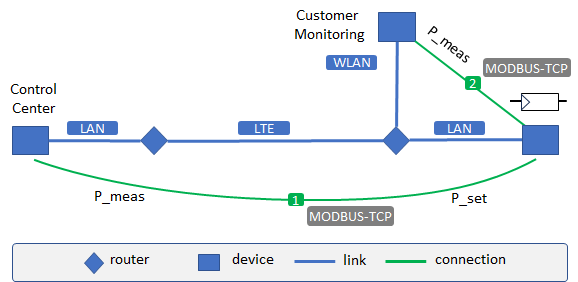

The network includes a PV plant (right side) with a controller device that is supposed to perform active power monitoring and curtailment. The peers for connection (1) are the PV controller and the control center. For (2), it's the PV controller and the customer monitoring software. The power measurement value is sent as information item from PV controller to both control center and customer monitoring. In the opposite direction, the control center may send an active power curtailment setpoint as information item to the PV controller. The connections all use MODBUS over TCP. This again is supported by all links even if they use different physical technologies. Information items can thus be transmitted without the need for protocol conversion. 

Connection 1 is modeled as follows:

This means that the PV controller is producing the power measurement, while the Control center produces the power setpoint. 
Connection 2 is modeled likewise:

The next graphic shows a somewhat more complex example using the same physical arrangement. This time the customer operates an energy management system (EMS) which may also provide a power curtailment setpoint to the PV controller. Furthermore the PV controller uses a different physical link: RS485. 

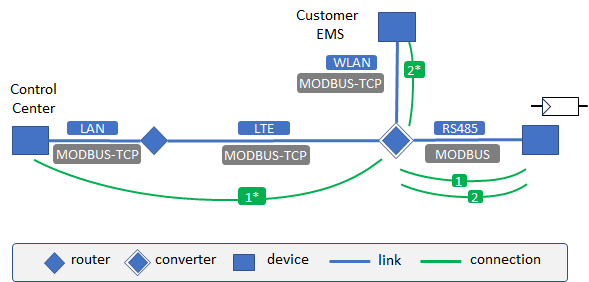

Although the controller still uses the MODBUS protocol, it is now mapped to RS485 which is non-TCP. Thus, a converter is needed to transmit information items over the TCP-based links. Note how introduction of the converter is modeled by creating additional connections. The power measurements are now sent from the PV controller over connections (1) and (1*) to the control center, and the power setpoints are sent from the control center to the PV controller over the same connections in the opposite direction. Hence, (1) and (1*) look as follows: 

Note that the info_items, peers and producer data is the same for both connections. Connections (2) and (2*) look the same, but the Control center is replaced by the Customer EMS:

This should allow the introduction of converters and the routing of information packages through the network, such that e.g. if there is a route for a given information item to travel from producing peer to consuming peer, or to calculate the latency for this. 